# 02 · Optimización y regularización de redes

**Objetivo:** comparar optimizadores sobre la misma red (implementados desde cero y verificados
contra `torch.optim`), elegir la tasa de aprendizaje, y ver sobreajuste y tres formas de
combatirlo: weight decay, dropout y early stopping.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_dl import Tensor, cross_entropy
from applied_dl.nn import MLP, SGD, Adam
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

X, y = load_digits(return_X_y=True)
X = X / 16.0
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)


def train(model, opt, Xt, yt, *, epochs=60, batch=64, Xv=None, yv=None, seed=0):
    g = np.random.default_rng(seed)
    hist = {"train": [], "val": []}
    for _ in range(epochs):
        model.train()
        for idx in np.array_split(g.permutation(len(Xt)), max(1, len(Xt) // batch)):
            opt.zero_grad()
            cross_entropy(model(Tensor(Xt[idx])), yt[idx]).backward()
            opt.step()
        model.eval()
        hist["train"].append(float(cross_entropy(model(Tensor(Xt)), yt).data))
        if Xv is not None:
            hist["val"].append(float(cross_entropy(model(Tensor(Xv)), yv).data))
    return hist

## 1. Optimizadores

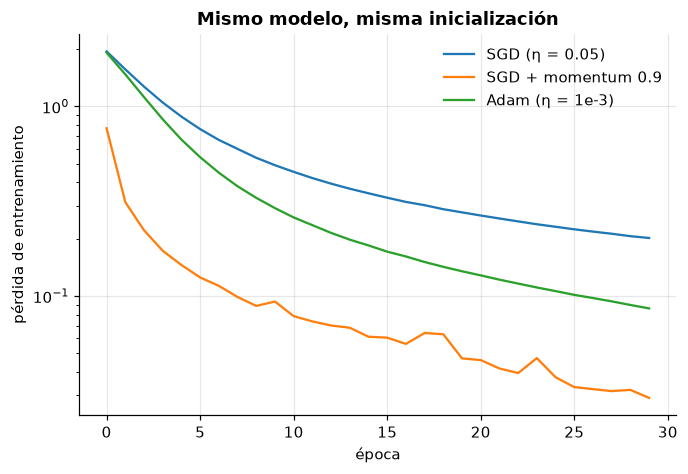

In [2]:
opts = {
    "SGD (η = 0.05)": lambda p: SGD(p, lr=0.05),
    "SGD + momentum 0.9": lambda p: SGD(p, lr=0.05, momentum=0.9),
    "Adam (η = 1e-3)": lambda p: Adam(p, lr=1e-3),
}
fig, ax = plt.subplots()
for name, make in opts.items():
    m = MLP([64, 128, 10], rng=np.random.default_rng(0))
    h = train(m, make(m.parameters()), Xtr, ytr, epochs=30)
    ax.semilogy(h["train"], label=name)
ax.set(
    xlabel="época", ylabel="pérdida de entrenamiento", title="Mismo modelo, misma inicialización"
)
ax.legend();

Momentum acumula velocidad en direcciones consistentes (lo visto en matemáticas aplicadas).
Adam además adapta el paso por parámetro con la magnitud reciente de su gradiente: es robusto
a la escala, por eso es el punto de partida habitual.

## 2. Tasa de aprendizaje

El hiperparámetro más importante. Se busca en escala logarítmica.

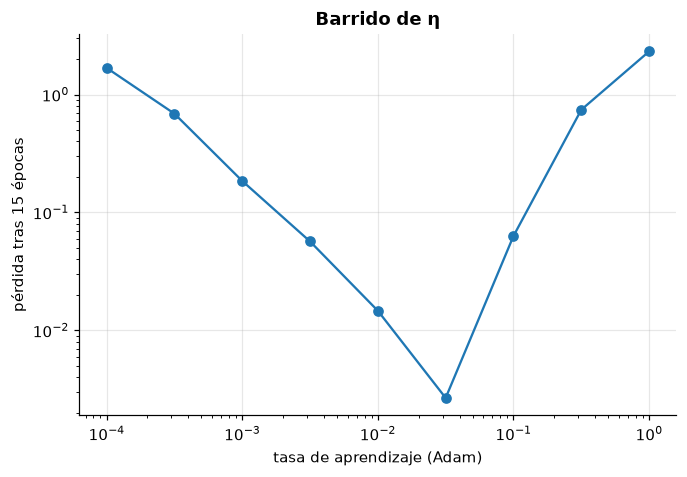

In [3]:
lrs = np.logspace(-4, 0, 9)
final = []
for lr in lrs:
    m = MLP([64, 128, 10], rng=np.random.default_rng(0))
    h = train(m, Adam(m.parameters(), lr=lr), Xtr, ytr, epochs=15)
    final.append(h["train"][-1])
fig, ax = plt.subplots()
ax.loglog(lrs, final, "o-")
ax.set(xlabel="tasa de aprendizaje (Adam)", ylabel="pérdida tras 15 épocas", title="Barrido de η");

## 3. Sobreajuste y regularización

150 ejemplos de entrenamiento con **20 % de etiquetas cambiadas al azar** y una red de dos capas
de 256: tiene capacidad de sobra para memorizar también el ruido. Miramos la pérdida de
**validación** (etiquetas limpias).

sin regularización             mejor val 0.654 en época   7 | final 1.237


weight decay (AdamW, λ = 1)    mejor val 0.672 en época   8 | final 0.892


dropout 0.5                    mejor val 0.591 en época  26 | final 0.989


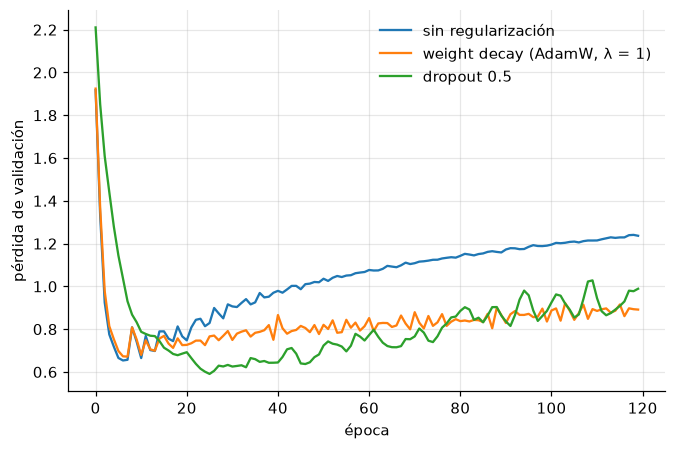

In [4]:
g = np.random.default_rng(1)
small = g.choice(len(Xtr), 150, replace=False)
Xs, ys = Xtr[small], ytr[small].copy()
noisy = g.random(len(ys)) < 0.2
ys[noisy] = g.integers(0, 10, noisy.sum())

variants = {
    "sin regularización": {"dropout": 0.0, "wd": 0.0},
    "weight decay (AdamW, λ = 1)": {"dropout": 0.0, "wd": 1.0},
    "dropout 0.5": {"dropout": 0.5, "wd": 0.0},
}
fig, ax = plt.subplots()
for name, v in variants.items():
    m = MLP([64, 256, 256, 10], dropout=v["dropout"], rng=np.random.default_rng(0))
    opt = Adam(m.parameters(), lr=3e-3, weight_decay=v["wd"], decoupled=True)
    h = train(m, opt, Xs, ys, epochs=120, batch=32, Xv=Xva, yv=yva)
    ax.plot(h["val"], label=name)
    best = int(np.argmin(h["val"]))
    print(
        f"{name:<30} mejor val {h['val'][best]:.3f} en época {best + 1:>3}"
        f" | final {h['val'][-1]:.3f}"
    )
ax.set(xlabel="época", ylabel="pérdida de validación")
ax.legend();

- Sin regularización, la validación toca fondo en pocas épocas y luego **sube**: la red pasa de
  aprender el patrón a memorizar las etiquetas ruidosas. Ese mínimo temprano es lo que
  **early stopping** detecta y conserva (`applied_dl.training.fit` restaura esos pesos).
- Weight decay y dropout frenan esa subida. Dropout además logra el mejor mínimo: impide que
  unidades individuales se especialicen en ejemplos concretos.
- Ojo con la escala de λ en AdamW: el decaimiento por paso es η·λ (aquí 3e-3), así que valores
  “típicos” como 0.01 apenas hacen efecto con tasas de aprendizaje pequeñas.

## Para llevar

- Empezar con Adam(W) y barrer η en escala log; momentum en SGD si se quiere exprimir el final.
- Medir siempre en validación: la pérdida de entrenamiento sola no dice nada de generalización.
- Weight decay, dropout y early stopping son baratos y complementarios.